# Task 2: Exploratory Data Analysis (EDA)

## Project: Customer Churn Analysis and Prediction

### Objective
Explore customer data to identify patterns and factors associated with customer churn.

### Analysis Areas
- Overall customer churn rate
- Customer demographics
- Tenure and monthly charges
- Contract types and payment methods
- Churn patterns across different customer groups

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall Churn Rate: 26.54%


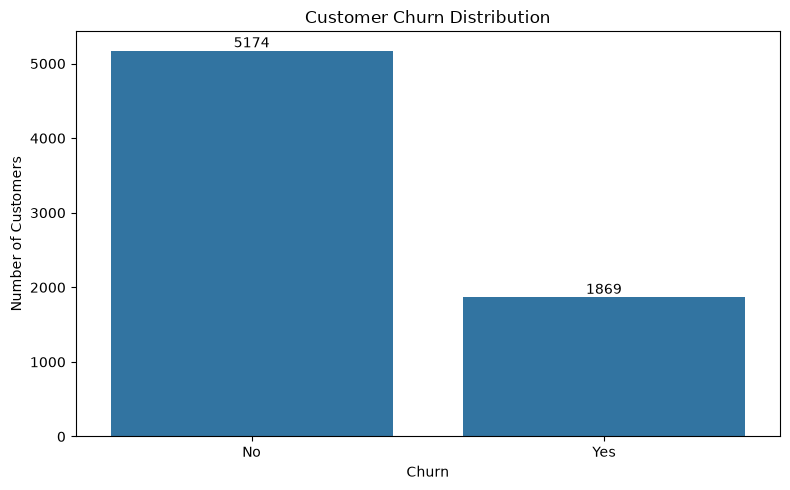

In [1]:

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv(
    r"D:\Saiket_Data_Analysis\data\Telco_Customer_Churn_Cleaned.csv"
)

# Display basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

# Calculate churn distribution
churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn Counts:")
print(churn_counts)

print("\nChurn Percentages:")
print(churn_percentages.round(2))

# Calculate overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall Churn Rate: {churn_rate:.2f}%")

# Visualize churn distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


### Key Findings – Overall Churn

- Total customers: 7,043.
- Customers who stayed: 5,174 (73.46%).
- Customers who left: 1,869 (26.54%).
- The overall churn rate is 26.54%.

**Insight:** Approximately one in four customers left the company, indicating a need for effective customer retention strategies.

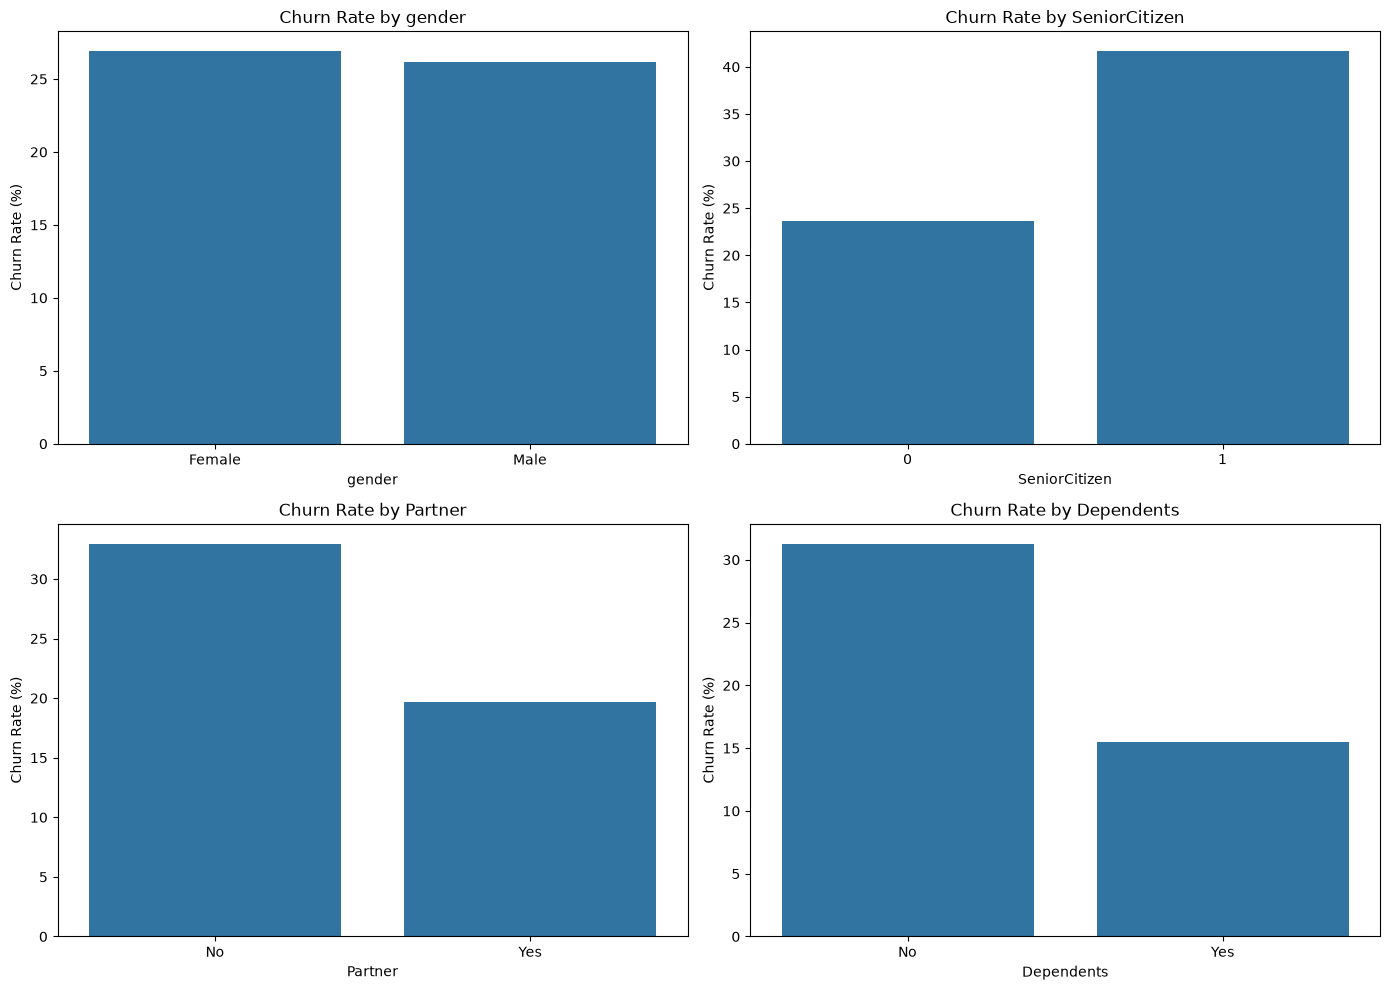


Churn Rate by gender:
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

Churn Rate by SeniorCitizen:
SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64

Churn Rate by Partner:
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Churn Rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


In [2]:

# Customer Demographics Analysis

demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(demographic_columns):

    churn_rate_by_group = (
        df.groupby(col, observed=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Churn Rate")
    )

    sns.barplot(
        data=churn_rate_by_group,
        x=col,
        y="Churn Rate",
        ax=axes[i]
    )

    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

# Display exact churn rates
for col in demographic_columns:
    print(f"\nChurn Rate by {col}:")
    print(
        (df.groupby(col, observed=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        ).round(2)
    )


### Key Findings – Customer Demographics

- Gender has little difference in churn rates:
  Female (26.92%) and Male (26.16%).

- Senior citizens have a significantly higher churn rate (41.68%) compared to non-senior citizens (23.61%).

- Customers without partners have a higher churn rate (32.96%) than customers with partners (19.66%).

- Customers without dependents have a higher churn rate (31.28%) compared to customers with dependents (15.45%).

**Insight:** Senior citizens and customers without partners or dependents represent customer groups with higher churn rates. These groups may benefit from targeted retention strategies.

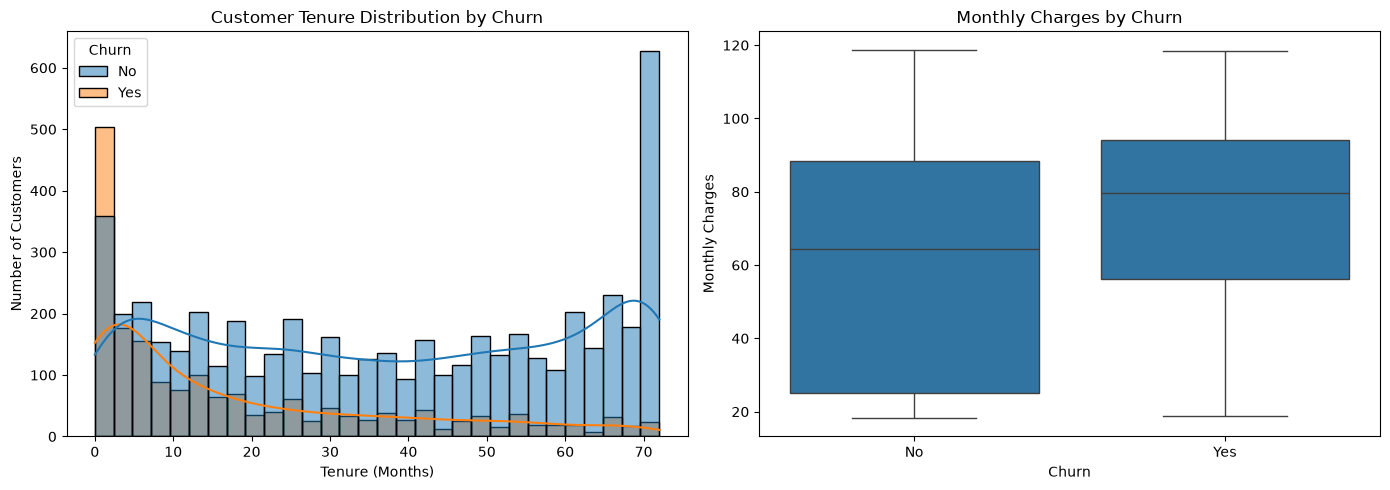

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average Monthly Charges by Churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [3]:

# Tenure and Monthly Charges Analysis

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure distribution by churn
sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Customer Tenure Distribution by Churn")
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Number of Customers")

# Monthly charges distribution by churn
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)

axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

# Compare average values
print("Average Tenure by Churn:")
print(df.groupby("Churn")["tenure"].mean().round(2))

print("\nAverage Monthly Charges by Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))


### Key Findings – Tenure and Monthly Charges

- Customers who stayed with the company had an average tenure of 37.57 months.
- Customers who churned had a much lower average tenure of 17.98 months.
- Customers who churned paid higher average monthly charges (74.44) compared to customers who stayed (61.27).

**Insight:** Customers with shorter subscription periods and higher monthly charges appear more likely to churn. The company should focus on improving the early customer experience and reviewing pricing or service value for higher-paying customers.

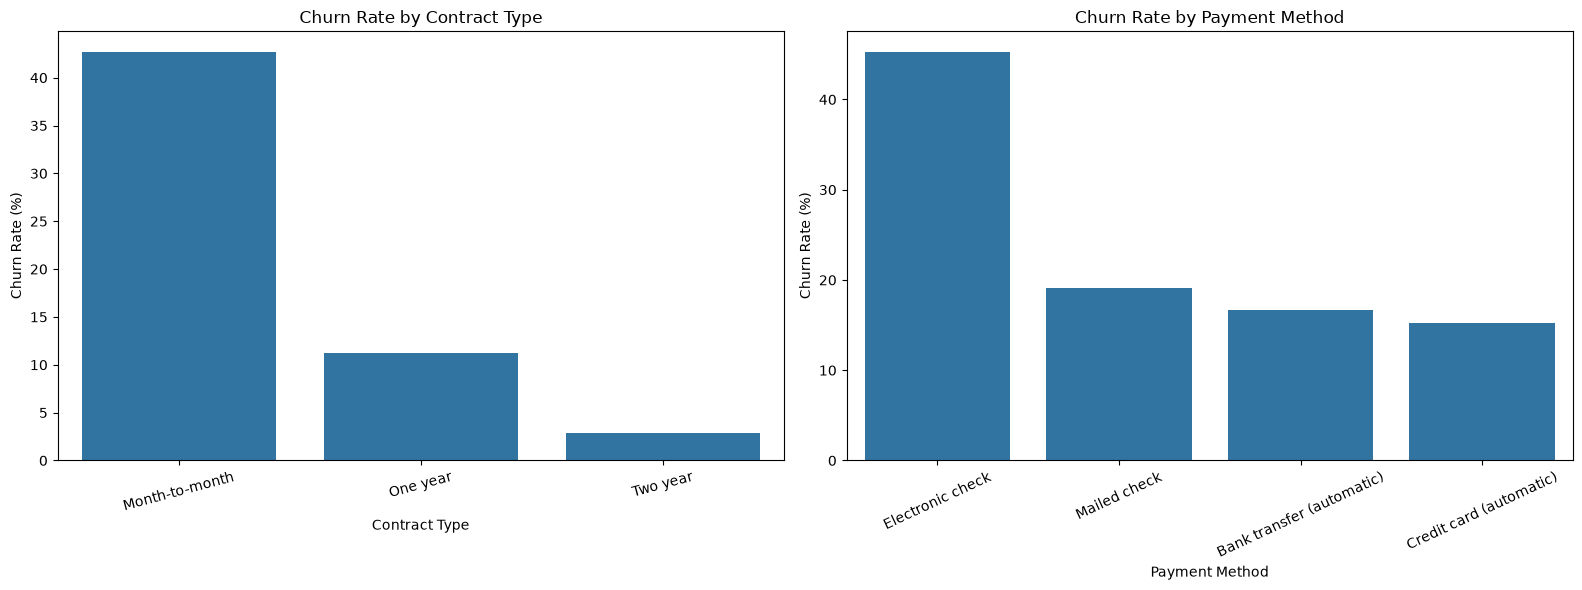

Churn Rate by Contract Type:
      Contract  Churn Rate
Month-to-month       42.71
      One year       11.27
      Two year        2.83

Churn Rate by Payment Method:
            PaymentMethod  Churn Rate
         Electronic check       45.29
             Mailed check       19.11
Bank transfer (automatic)       16.71
  Credit card (automatic)       15.24


In [4]:
# Churn Analysis by Contract Type and Payment Method

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Churn rate by contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
    .sort_values("Churn Rate", ascending=False)
)

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate",
    ax=axes[0]
)

axes[0].set_title("Churn Rate by Contract Type")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_xlabel("Contract Type")
axes[0].tick_params(axis="x", rotation=15)

# Churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
    .sort_values("Churn Rate", ascending=False)
)

sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="Churn Rate",
    ax=axes[1]
)

axes[1].set_title("Churn Rate by Payment Method")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_xlabel("Payment Method")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

print("Churn Rate by Contract Type:")
print(contract_churn.round(2).to_string(index=False))

print("\nChurn Rate by Payment Method:")
print(payment_churn.round(2).to_string(index=False))

### Key Findings – Contract Types and Payment Methods

**Contract Type:**
- Month-to-month customers have the highest churn rate (42.71%).
- One-year contract customers have a churn rate of 11.27%.
- Two-year contract customers have the lowest churn rate (2.83%).

**Payment Method:**
- Electronic check users have the highest churn rate (45.29%).
- Mailed check users have a churn rate of 19.11%.
- Automatic bank transfer users have a churn rate of 16.71%.
- Automatic credit card users have the lowest churn rate (15.24%).

**Insight:** Customers with month-to-month contracts and those using electronic checks are more likely to churn. The company could encourage longer-term contracts and promote automatic payment methods to improve customer retention.

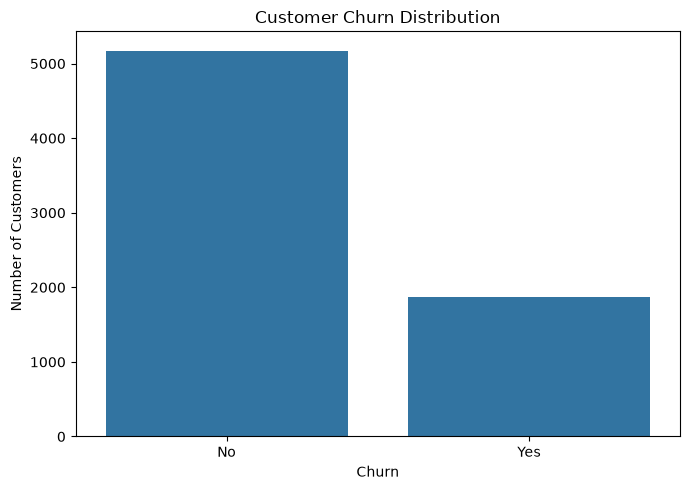

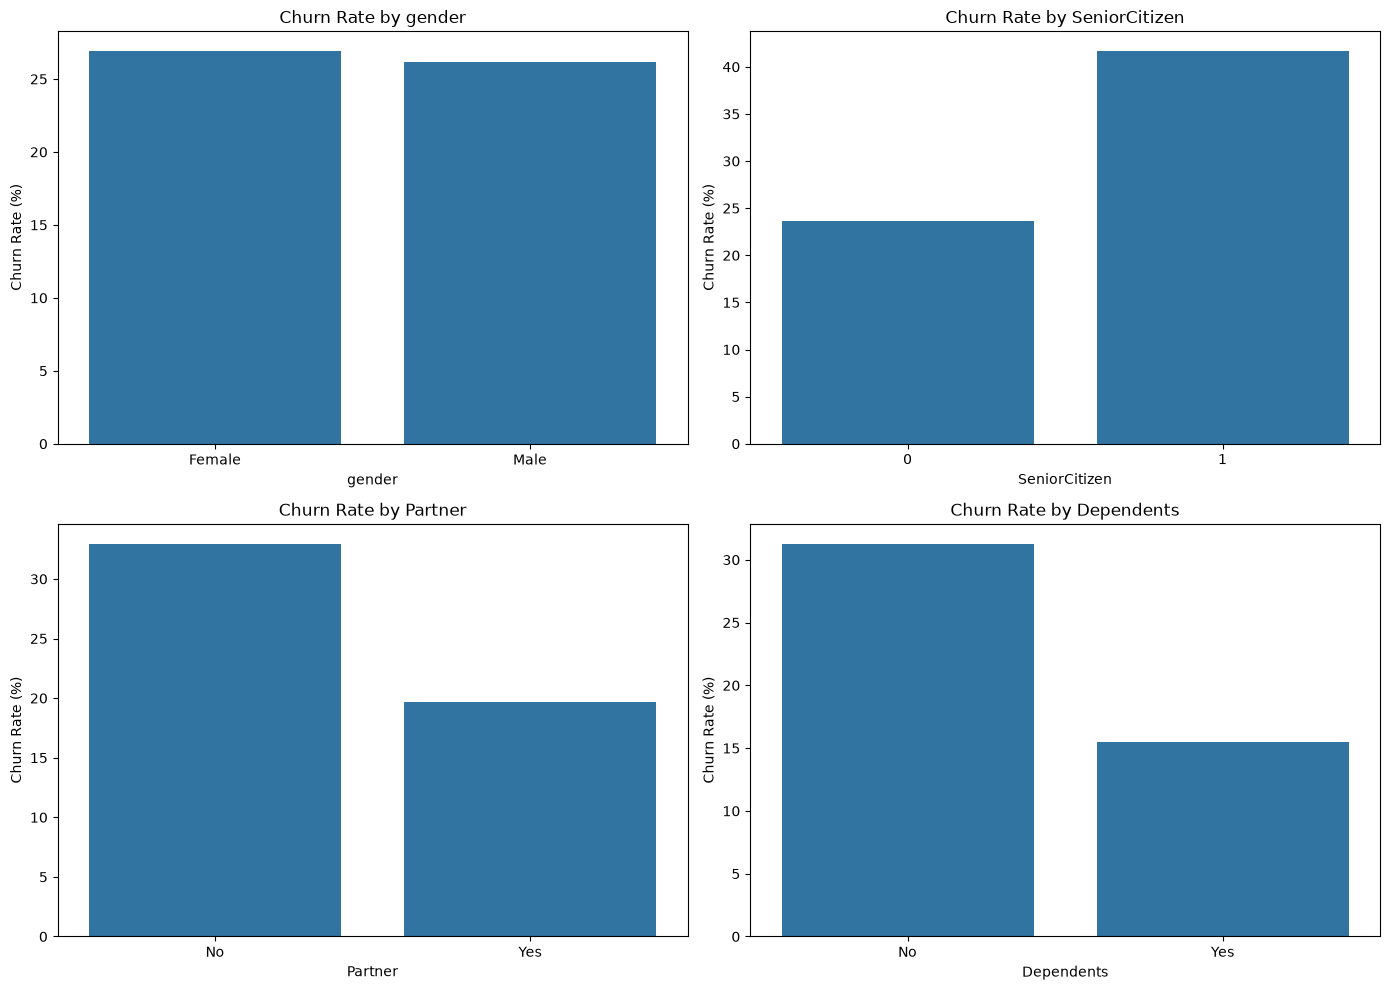

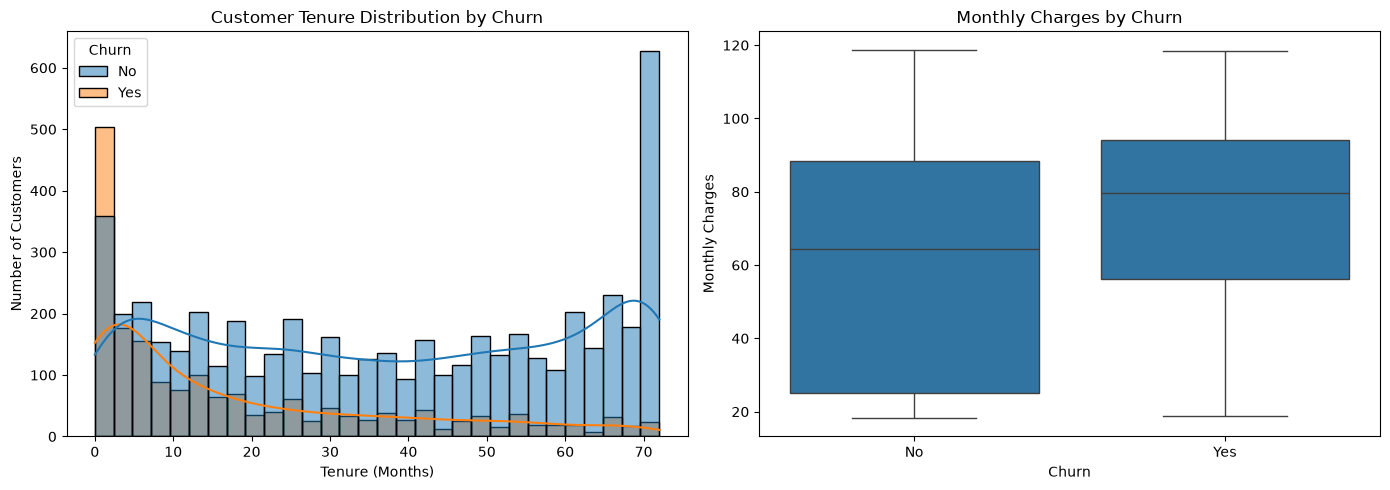

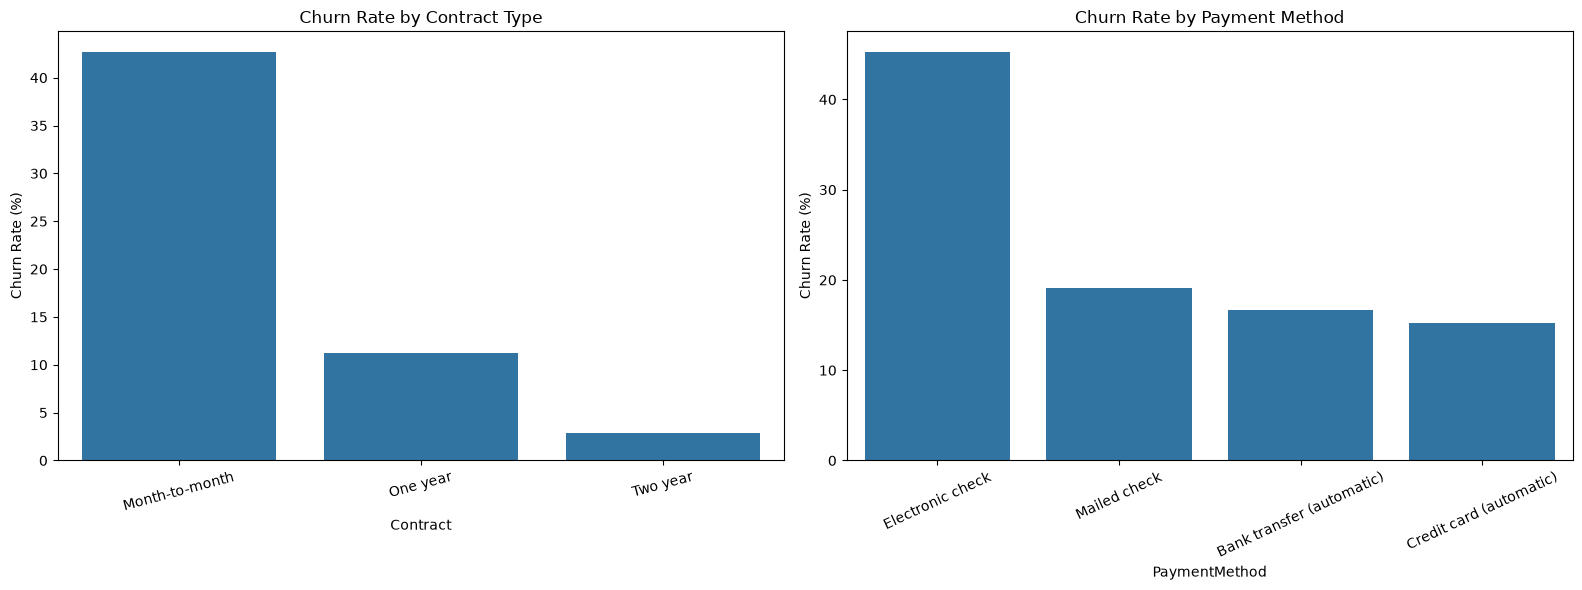

Saved visualization files:
01_overall_churn.png
02_demographics_churn.png
03_tenure_monthly_charges.png
04_contract_payment_churn.png


In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Create the visualizations folder if it doesn't exist
output_dir = Path(r"D:\Saiket_Data_Analysis\visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Overall Churn Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(output_dir / "01_overall_churn.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. Churn Rate by Demographics
demographic_columns = ["gender", "SeniorCitizen", "Partner", "Dependents"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(demographic_columns):
    rates = (
        df.groupby(col)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Churn Rate")
    )

    sns.barplot(data=rates, x=col, y="Churn Rate", ax=axes[i])
    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.savefig(output_dir / "02_demographics_churn.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Tenure and Monthly Charges
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="tenure", hue="Churn",
    bins=30, kde=True, ax=axes[0]
)
axes[0].set_title("Customer Tenure Distribution by Churn")
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Number of Customers")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.savefig(output_dir / "03_tenure_monthly_charges.png", dpi=300, bbox_inches="tight")
plt.show()


# 4. Contract Type and Payment Method
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
    .sort_values("Churn Rate", ascending=False)
)

sns.barplot(data=contract_churn, x="Contract", y="Churn Rate", ax=axes[0])
axes[0].set_title("Churn Rate by Contract Type")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=15)

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
    .sort_values("Churn Rate", ascending=False)
)

sns.barplot(data=payment_churn, x="PaymentMethod", y="Churn Rate", ax=axes[1])
axes[1].set_title("Churn Rate by Payment Method")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(output_dir / "04_contract_payment_churn.png", dpi=300, bbox_inches="tight")
plt.show()


# Confirm saved files
print("Saved visualization files:")
for file in sorted(output_dir.glob("*.png")):
    print(file.name)

## EDA Summary and Conclusions

The Exploratory Data Analysis revealed several patterns associated with customer churn:

1. **Overall Churn:** 26.54% of customers left the company.
2. **Demographics:** Senior citizens and customers without partners or dependents showed higher churn rates.
3. **Tenure:** Customers who churned had a lower average tenure (17.98 months) compared to customers who stayed (37.57 months).
4. **Monthly Charges:** Customers who churned had higher average monthly charges (74.44) than customers who stayed (61.27).
5. **Contract Type:** Month-to-month contracts had the highest churn rate (42.71%), while two-year contracts had the lowest (2.83%).
6. **Payment Method:** Electronic check users had the highest churn rate (45.29%).

### Business Recommendations

- Improve onboarding and customer support for new customers.
- Review pricing and service value for customers with higher monthly charges.
- Encourage customers to consider long-term contracts.
- Promote automatic payment methods.
- Develop targeted retention campaigns for customer groups with higher churn rates.

**Conclusion:** Contract type, payment method, tenure, and monthly charges show notable associations with customer churn. These findings can help the company identify at-risk customer groups and develop more effective retention strategies.